In [1]:
# imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from scipy import stats


# Data preprocessing
### Includes any change made to the data before applying feature selection: imputation, normalisation, bootstrapping,

Process for CW1 went as follows:

Classification
1. One hot encoding (categorical features to binary) | Imputation (using mode, old method) 
Note: there were null values '?' that were not handled before one hot encoding
2. Normalisation (MinMax, numerical features -> 0-1 range)

Regression
1. Imputation (removed null data, mean for continuous, mode for categorical)
2. Normalisation (MinMax)
3. One hot encoding (pd.get_dummies)

Possible other methods for preprocessing include:
- Removing outliers
- VAE/Bootstrapping
    - Generating new instances from not a lot of data
        - Training data after removing outliers

And some more implicit methods include:
- Separating data into features and outcomes/labels

In [ ]:
# viewing data and datatypes (numerical / categorical)
dataset = pd.read_csv("./datasets/TrainDataset2025.csv")

dataset.info()
dataset.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Columns: 121 entries, ID to original_ngtdm_Strength
dtypes: float64(108), int64(12), object(1)
memory usage: 378.2+ KB


In [ ]:
# Split data into features and outcomes

## Outcomes
dataset_y_clf = dataset['pCR (outcome)']
datasey_y_reg = dataset['RelapseFreeSurvival (outcome)']

## Features
dataset_x_all = dataset.drop(['pCR (outcome)', 'RelapseFreeSurvival (outcome)'], axis=1)

dataset_x_all

## Type-specific preprocessing
### Dataset datatypes include: object, float64 and int64
    # object: ID Column
    # float64: Continuous features
    # int64: Categorical features

### Handling object datatype
1. Remove object datatype

This only contains the ID column

In [ ]:
# Handling object datatype
print(dataset.select_dtypes(object)) # ID Column

print("Before: "+str(dataset.select_dtypes(object).shape))

dataset = dataset.drop("ID",axis=1)
print("After: "+str(dataset.select_dtypes(object).shape))


            ID
0    TRG002174
1    TRG002178
2    TRG002204
3    TRG002206
4    TRG002210
..         ...
395  TRG002948
396  TRG002954
397  TRG002958
398  TRG002961
399  TRG002962

[400 rows x 1 columns]
Before: (400, 1)
After: (400, 0)


### Handling int64 datatype
#### Categorical Features
1. Remove non-categorical features

'original_shape_VoxelVolume' feature is int, but not categorical data (doesn't use classes)

Truncate Age feature to make it consistent with other clinical features

In [ ]:
print(dataset.select_dtypes(np.int64))

print("Before: "+str(dataset.select_dtypes(np.int64).shape))

dataset['Age'] = dataset['Age'].astype(np.int64)

dataset['original_shape_VoxelVolume'] = dataset['original_shape_VoxelVolume'].astype(np.float64)


print("After: "+str(dataset.select_dtypes(np.int64).shape))

# Save column names of categorical features for later
categorical_names = dataset.select_dtypes(np.int64).columns
categorical_names

     pCR (outcome)  ER  PgR  HER2  TrippleNegative  ChemoGrade  Proliferation  \
0                1   0    0     0                1           3              3   
1                0   1    1     0                0           3              3   
2                1   0    0     0                1           2              1   
3                0   0    0     0                1           3              3   
4                0   1    0     0                0           2              1   
..             ...  ..  ...   ...              ...         ...            ...   
395              0   1    0     1                0           3              2   
396              0   0    0     0                1           3              3   
397              0   0    0     0                1           2              1   
398              0   1    0     0                0           3              3   
399              0   1    0     0                0           2              1   

     HistologyType  LNStatu

Index(['pCR (outcome)', 'ER', 'PgR', 'HER2', 'TrippleNegative', 'ChemoGrade',
       'Proliferation', 'HistologyType', 'LNStatus', 'TumourStage', 'Gene'],
      dtype='object')

### Handling float64 datatype
#### Continuous Features

Nothing specific left, data is all continuous

In [ ]:
# Save column names of continuous features for later
dataset.select_dtypes(np.float64)
continuous_names = dataset.select_dtypes(np.float64).columns
continuous_names

Index(['RelapseFreeSurvival (outcome)', 'Age', 'original_shape_Elongation',
       'original_shape_Flatness', 'original_shape_LeastAxisLength',
       'original_shape_MajorAxisLength',
       'original_shape_Maximum2DDiameterColumn',
       'original_shape_Maximum2DDiameterRow',
       'original_shape_Maximum2DDiameterSlice',
       'original_shape_Maximum3DDiameter',
       ...
       'original_glszm_SmallAreaHighGrayLevelEmphasis',
       'original_glszm_SmallAreaLowGrayLevelEmphasis',
       'original_glszm_ZoneEntropy', 'original_glszm_ZonePercentage',
       'original_glszm_ZoneVariance', 'original_ngtdm_Busyness',
       'original_ngtdm_Coarseness', 'original_ngtdm_Complexity',
       'original_ngtdm_Contrast', 'original_ngtdm_Strength'],
      dtype='object', length=109)

## General Preprocessing
1. Null handling (converting '999')
2. Train-test split
3. Outlier handling
4. Data Imputation
5. Balancing data (Frequency handling)
6. Data Normalisation | One-hot Encoding

### 1. Null Handling
Issue: Can't replace all '999' with np.nan. This converts int64 to float64 as NaN is float64
- Solution: by saving column names, in datatype-specific handling, for int64 (categorical) features, no longer a need to preserve int64 as no data is lost when converting to float

In [ ]:
# Replace 999 (placeholder) with actual null values
dataset = dataset.replace([999],np.nan)

# Viewing features with null values
non_null = dataset.isnull().sum()
non_null = non_null[non_null > 0]
non_null

pCR (outcome)       5
PgR                 1
HER2                1
TrippleNegative     1
ChemoGrade          3
Proliferation       2
HistologyType       3
LNStatus            1
Gene               88
dtype: int64

### 2. Train-test split

In [ ]:
# Split the dataset into 80% for training data and 20% for test data with stratified splitting to keep the balance of 0 and 1 classes in the training and test sets roughly the same
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 12, stratify = y)

### 3. Outlier Removal
Options: 
1. Z-Score
2. Interquartile Range

[Other Model-based methods:](https://www.geeksforgeeks.org/machine-learning/machine-learning-outlier/)

3. Isolation Forest
4. Local Outlier Factor
5. DBSCAN(?)

[Even More Model-based Methods](https://scikit-learn.org/stable/modules/outlier_detection.html#:~:text=OK-,2.7.1.%20Overview%20of%20outlier%20detection%20methods,-%23)

<Axes: >

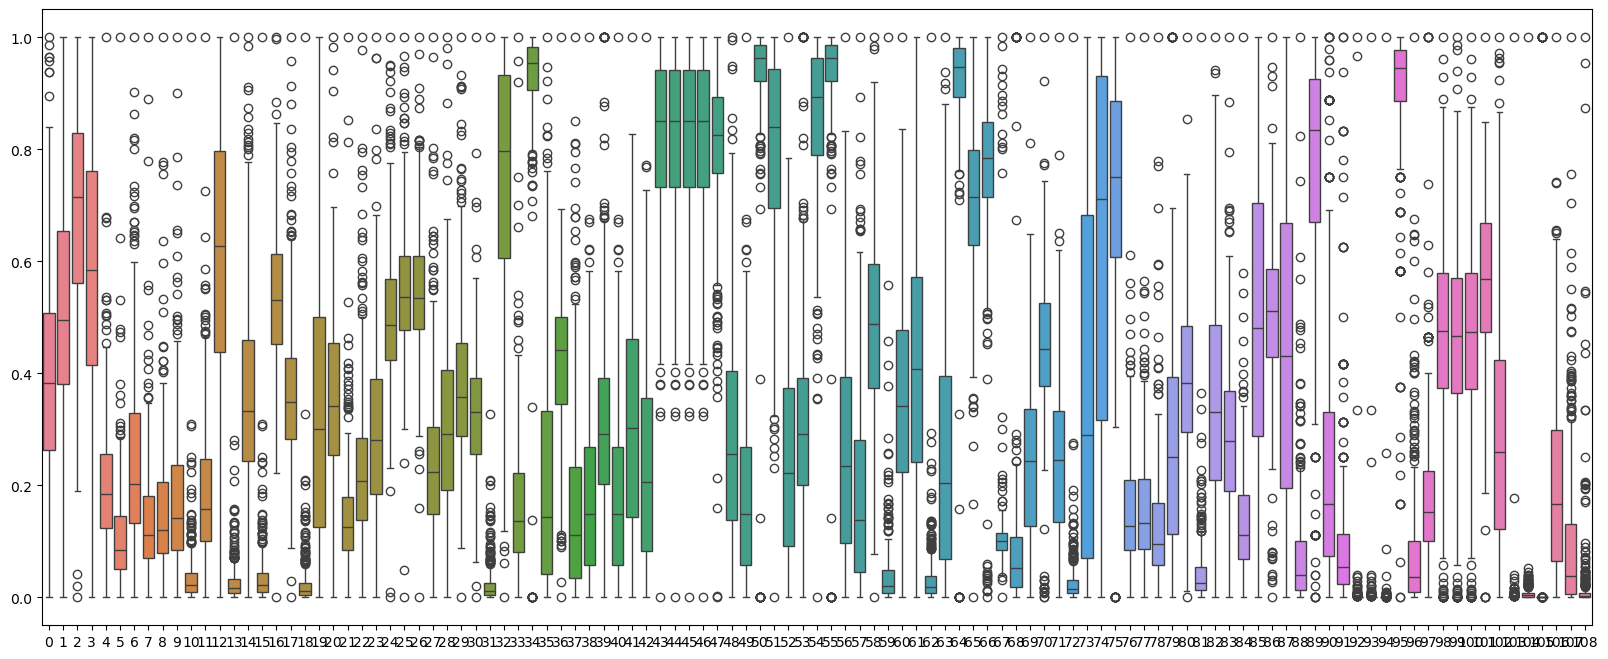

In [ ]:
# Data visualisation
scaler = MinMaxScaler()

# Boxplot below shows normalised continuous features + outliers
fig,ax=plt.subplots(1,figsize=(20,8))
sns.boxplot(data=scaler.fit_transform(dataset[continuous_names]),ax=ax)

Note: Above boxplot, categorical features normalised to 0-1 range, shows prevalence of outliers. Handling using naive methods, such as Z-score or IQR, may be ineffective

##### Option 1 - Z-score

In [ ]:
# Printing outlier locations
z_scores = np.abs(stats.zscore(dataset))
outliers_zscore = np.where(z_scores > 3)
outlier_indices = list(zip(outliers_zscore[0], outliers_zscore[1]))

print("Outlier total: "+str(len(outlier_indices)))
for index in outlier_indices:
    print(index)

Outlier total: 576
(np.int64(0), np.int64(1))
(np.int64(1), np.int64(1))
(np.int64(6), np.int64(1))
(np.int64(8), np.int64(1))
(np.int64(9), np.int64(1))
(np.int64(32), np.int64(100))
(np.int64(32), np.int64(101))
(np.int64(32), np.int64(102))
(np.int64(32), np.int64(106))
(np.int64(34), np.int64(102))
(np.int64(34), np.int64(106))
(np.int64(34), np.int64(119))
(np.int64(37), np.int64(100))
(np.int64(37), np.int64(101))
(np.int64(37), np.int64(102))
(np.int64(37), np.int64(106))
(np.int64(54), np.int64(45))
(np.int64(54), np.int64(50))
(np.int64(54), np.int64(61))
(np.int64(54), np.int64(64))
(np.int64(54), np.int64(66))
(np.int64(54), np.int64(75))
(np.int64(54), np.int64(77))
(np.int64(54), np.int64(78))
(np.int64(54), np.int64(79))
(np.int64(54), np.int64(81))
(np.int64(54), np.int64(86))
(np.int64(54), np.int64(90))
(np.int64(54), np.int64(108))
(np.int64(54), np.int64(112))
(np.int64(54), np.int64(116))
(np.int64(57), np.int64(48))
(np.int64(57), np.int64(68))
(np.int64(59), np.in

In [ ]:
# Applying z-score

dataset[(np.abs(stats.zscore(dataset)) < 3).all(axis=1)] # < 3 checks for rows where all features are 3 standard deviations from the mean

,pCR (outcome),RelapseFreeSurvival (outcome),Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength


Note: Z-score is clearly ineffective. Implication from above cell is that outliers are prevalent in all samples, hence they are all removed

##### Option 2 - Interquartile Range

In [ ]:
# Calculating Interquartile Range
Q1 = dataset.quantile(0.25)
Q3 = dataset.quantile(0.75)
IQR = Q3 - Q1

In [ ]:
# Outputting number of outliers per column
outliers_iqr = ((dataset < (Q1 - 1.5 * IQR)) | (dataset > (Q3 + 1.5 * IQR)))

print("Number of outliers per column:")
outliers_col = outliers_iqr.sum()
outliers_col = outliers_col[outliers_col > 0]

print(outliers_col)

Number of outliers per column:
pCR (outcome)                     84
RelapseFreeSurvival (outcome)      8
HistologyType                     59
original_shape_Elongation          3
original_shape_LeastAxisLength    13
                                  ..
original_ngtdm_Busyness           35
original_ngtdm_Coarseness         61
original_ngtdm_Complexity          6
original_ngtdm_Contrast           36
original_ngtdm_Strength           59
Length: 102, dtype: int64


In [ ]:
# Applying IQR (incomplete)
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR

upper_arr = np.where(dataset >= upper)[0]
lower_arr = np.where(dataset <= lower)[0]

# dataset.drop(index=upper_arr, inplace=True)
# dataset.drop(index=lower_arr, inplace=True)

##### Option 2.5 - Combine Z-score and IQR

In [ ]:
# Handle outliers in columns of continuous features using Interquartile Range of the columns
for col in continuous_names:
    lower_quartile = X_train[col].quantile(0.25)
    upper_quartile = X_train[col].quantile(0.75)
    iqr = upper_quartile - lower_quartile

    lower_bound = lower_quartile - 1.5 * iqr
    upper_bound = upper_quartile + 1.5 * iqr
    
    X_train[col] = np.where((X_train[col] < lower_bound) | (X_train[col] > upper_bound), X_train[col].median(), X_train[col])


In [ ]:
# Apply Z-Score Normalisation to the columns for the continuous features
standard_scaler = StandardScaler()
X_train[continuous_names] = standard_scaler.fit_transform(X_train[continuous_names])
fig, ax = plt.subplots(1, figsize = (20, 8))
sns.boxplot(data = X_train[continuous_names], ax = ax)

##### Option 3 - Isolation Forest
Method of anomaly detection that isolates outliers by building decision trees based on multiple splits. Supposedly better for high dimensions [[reference]](https://www.geeksforgeeks.org/machine-learning/machine-learning-outlier/#:~:text=IQR%20Method-,3.%20Isolation%20Forest,-Isolation%20Forest%20is)

Params include: contamination, random state and bootstrap [(among others that may be useful)](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html#:~:text=IsolationForest-,IsolationForest,-%23)
- contamination (float) is the percentage of outliers
- random state (int) is the pseudorandom seed
- bootstrap (bool) is an option to enable random sampling with replacement

IsoForest_Outlier
 1    380
-1     20
Name: count, dtype: int64


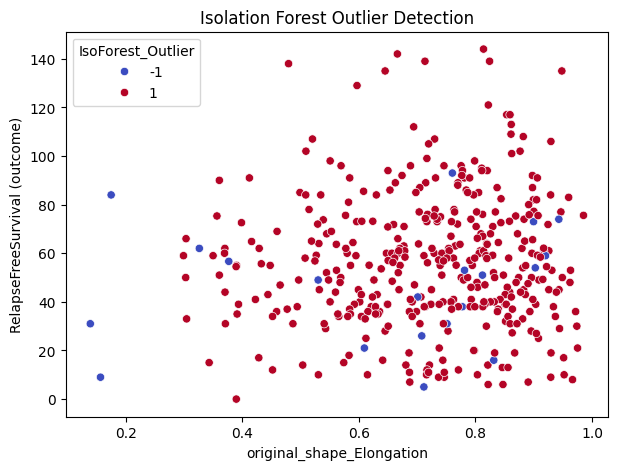

In [ ]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.05, random_state=42, bootstrap=True)
y_pred_iso = iso.fit_predict(dataset)

dataset["IsoForest_Outlier"] = y_pred_iso
print(dataset["IsoForest_Outlier"].value_counts())

plt.figure(figsize=(7, 5))
sns.scatterplot(x="original_shape_Elongation", y="RelapseFreeSurvival (outcome)", data=dataset,
                hue="IsoForest_Outlier", palette="coolwarm")
plt.title("Isolation Forest Outlier Detection")
plt.show()

Index(['RelapseFreeSurvival (outcome)', 'Age', 'original_shape_Elongation',
       'original_shape_Flatness', 'original_shape_LeastAxisLength',
       'original_shape_MajorAxisLength',
       'original_shape_Maximum2DDiameterColumn',
       'original_shape_Maximum2DDiameterRow',
       'original_shape_Maximum2DDiameterSlice',
       'original_shape_Maximum3DDiameter',
       ...
       'original_glszm_SmallAreaHighGrayLevelEmphasis',
       'original_glszm_SmallAreaLowGrayLevelEmphasis',
       'original_glszm_ZoneEntropy', 'original_glszm_ZonePercentage',
       'original_glszm_ZoneVariance', 'original_ngtdm_Busyness',
       'original_ngtdm_Coarseness', 'original_ngtdm_Complexity',
       'original_ngtdm_Contrast', 'original_ngtdm_Strength'],

### 3. Data Imputation
Performed after outlier handling as imputation should perform better with clean(er) data, especially for null values

Null values can be removed or imputed, or a combination of both consider only removing Gene null values, as other null totals are [minimal](#1-null-handling)  
- SimpleImputer for imputation by mean/mode/median
- IterativeImputer for model-based imputation

##### SimpleImputer

Options:
1. Removal of all null values
2. Partial Removal, Partial Imputation
3. Imputation of all null values

This has a 'missing_values' field, meaning we could set said field to 999 instead of the earlier conversion of 999 to NaN
- Prefer not to do so as '999' would negatively affect algorithms

##### 1. Removal of all null values
Majority of null values are from one feature ('Gene'). Is it worth removing them all?

In [ ]:
# # Removal (entirely)
# dataset = dataset.dropna()

##### 2. Partial Removal, Partial Imputation
1. Removing Gene
2. Imputing other features (format: x|y -> continuous|categorical)

    2.1 Mean|Mode Imputation

    2.2 Mode|Mode Imputation

Impute continuous features using the mean and categorical features using the mode

Removes the majority of outliers ('Gene'), imputes the rest.

In [ ]:
imputer_mean = SimpleImputer(strategy='mean')
imputer_mode = SimpleImputer(strategy='most_frequent')

In [ ]:
## 1. Removing Gene
dataset['Gene'].dropna()

## 2. Imputing other features (format: x|y -> continuous|categorical)
    
### 2.1 Mean|Mode
dataset[continuous_names] = imputer_mean.fit_transform(dataset[continuous_names])
dataset[categorical_names] = imputer_mode.fit_transform(dataset[categorical_names])

# ### 2.2 Mode|Mode
# dataset[continuous_names] = imputer_mode.fit_transform(dataset[continuous_names])
# dataset[categorical_names] = imputer_mode.fit_transform(dataset[categorical_names])


# Outputting null values: none remaining
non_null = dataset.isnull().sum()
non_null = non_null[non_null > 0]
non_null

Series([], dtype: int64)

##### 3. Imputation of all null values

(format: x|y -> continuous|categorical)
1. Imputing using mean|mode
2. Imputing using the median|mode


Added this case for comparison

Mean|Mode Imputation

In [ ]:
# dataset[continuous_names] = imputer_mean.fit_transform(dataset[continuous_names])
# dataset[categorical_names] = imputer_mode.fit_transform(dataset[categorical_names])

Median|Mode Imputation

(Median is less sensitive to outliers)

In [ ]:
# For the continuous features, impute the missing values in each column with the median of that column
#median_imputer = SimpleImputer(missing_values = np.nan, strategy = 'median')
#X_train[continuous_names] = median_imputer.fit_transform(X_train[continuous_names])
#X_train[continuous_names].head()

In [ ]:
fig, ax = plt.subplots(1, figsize = (20, 8))
sns.boxplot(data = X_train[continuous_names], ax = ax)

##### IterativeImputer

1. Nearest neighbour imputation (different scales in features may be punishing)

Allows for models to determine imputation

[This](https://scikit-learn.org/stable/modules/impute.html#multiple-vs-single-imputation:~:text=of%20IterativeImputer.-,7.4.3.2.%20Multiple%20vs.%20Single%20Imputation,-%23) might be helpful

### 4. Balancing
We can use stratification when building models to make sure the data is split in the same way as the distribution. We should, therefore, clean up the distribution of data
- Applies for classification as we split based on discrete outcome
- Question: How do we apply to regression?

1. Classification (pCR (outcome))
2. Regression (RelapseFreeSurvival (outcome))

##### 1. Classification (pCR (outcome))
Use a histogram to view relative frequencies

pCR (outcome)
0.0    316
1.0     84
Name: count, dtype: int64


<Axes: xlabel='pCR (outcome)', ylabel='count'>

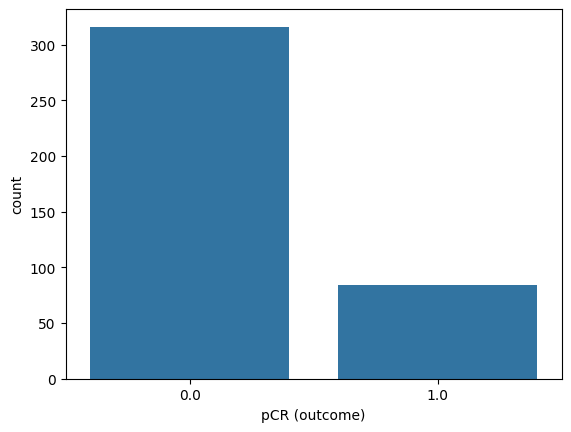

In [ ]:
# pCR (outcome) visualisation
print(dataset['pCR (outcome)'].value_counts())

# sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
sns.countplot(x="pCR (outcome)", data=dataset)

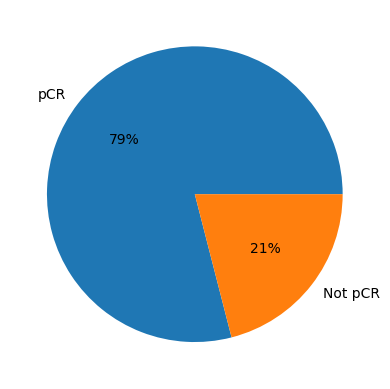

In [ ]:
# Pie chart

plt.pie(dataset['pCR (outcome)'].value_counts(), labels=['pCR', 'Not pCR'], autopct='%.f%%')
plt.show()

In [ ]:
# Balancing? Then see effect on distribution?

##### 2. Regression (RelapseFreeSurvival (outcome))

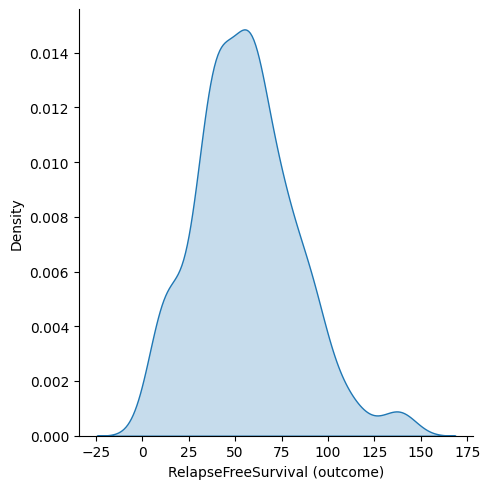

In [ ]:
sns.displot(x="RelapseFreeSurvival (outcome)", data=dataset, kind="kde", fill=True)

In [ ]:
# Balancing?

### 5.a Normalisation
Options:
1. MinMax
2. Z-normalisation
3. Vector Normalisation
4. More research: https://www.geeksforgeeks.org/python/data-normalization-with-pandas/

##### 1. MinMax

<Axes: >

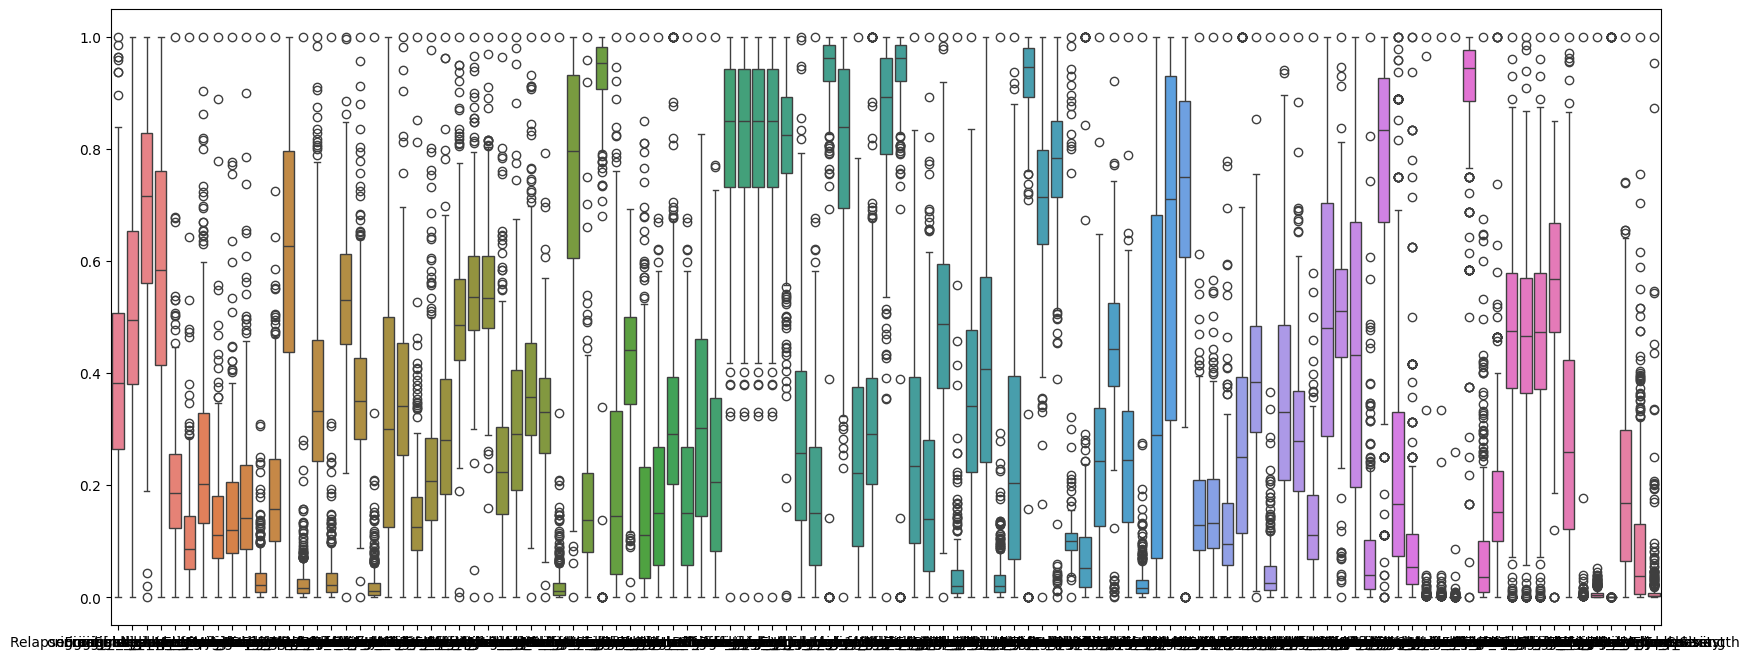

In [ ]:
scaler = MinMaxScaler()
dataset[continuous_names] = scaler.fit_transform(dataset[continuous_names])
dataset[continuous_names]

fig,ax=plt.subplots(1,figsize=(20,8))
sns.boxplot(data=dataset[continuous_names],ax=ax)

In [ ]:
dataset.to_csv("./datasets/PreProcessedDataset.csv",index=False)

##### 5.b One-hot Encoding

In [ ]:
# Apply One-Hot Encoding to the columns for the categorical features
X_train_encoded = pd.get_dummies(X_train, columns = categorical_names, drop_first = True)
X_train_encoded

In [ ]:
# Check that there are no longer any missing values for the features of each data point
missing_values = X_train_encoded.isnull().sum()
missing_values = missing_values[missing_values > 0]
missing_values

<h2>Preprocessing for Classification Task</h2>

In [2]:
dataset2 = pd.read_csv("./datasets/TrainDataset2025.csv")

dataset2.head()

,ID,pCR (outcome),RelapseFreeSurvival (outcome),Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,TRG002174,1,144.0,41.0,0,0,0,1,3,3,...,0.517172,0.375126,3.325332,0.002314,3880771.500,473.464852,0.000768,0.182615,0.030508,0.000758
1,TRG002178,0,142.0,39.0,1,1,0,0,3,3,...,0.444391,0.444391,3.032144,0.005612,2372009.744,59.459710,0.004383,0.032012,0.001006,0.003685
2,TRG002204,1,135.0,31.0,0,0,0,1,2,1,...,0.534549,0.534549,2.485848,0.006752,1540027.421,33.935384,0.007584,0.024062,0.000529,0.006447
3,TRG002206,0,12.0,35.0,0,0,0,1,3,3,...,0.506185,0.506185,2.606255,0.003755,6936740.794,46.859265,0.005424,0.013707,0.000178,0.004543
4,TRG002210,0,109.0,61.0,1,0,0,0,2,1,...,0.462282,0.462282,2.809279,0.006521,1265399.054,39.621023,0.006585,0.034148,0.001083,0.005626


In [3]:
# Select and assign feature columns to x
x = dataset2.drop(['ID', 'pCR (outcome)', 'RelapseFreeSurvival (outcome)'], axis = 1)
# Select and assign label column to y
y = dataset2['pCR (outcome)']

# Check the distribution of 0 and 1 for the label column PCR to determine if classes are imbalanced and so if stratified splitting should be used
y.value_counts()

pCR (outcome)
0      311
1       84
999      5
Name: count, dtype: int64

In [4]:
# Split the dataset into 80% for training data and 20% for test data with stratified splitting to keep the balance of 0 and 1 classes in the training and test sets roughly the same
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 12, stratify = y)

In [5]:
# Select the columns of the categorical features. These features correspond to the clinical features
X_train['Age'] = X_train['Age'].astype(np.int64)
X_train['original_shape_VoxelVolume'] = X_train['original_shape_VoxelVolume'].astype(np.float64)
categorical_names = X_train.select_dtypes(np.int64).columns
X_train[categorical_names]

,Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,Gene
365,54,1,1,0,0,2,1,1,1,3,999
172,67,0,0,1,0,2,1,1,0,3,1
183,35,0,0,0,1,2,1,1,0,3,1
299,67,1,0,0,0,2,1,1,1,2,0
321,74,1,0,0,0,2,1,2,0,2,0
...,...,...,...,...,...,...,...,...,...,...,...
200,57,1,0,1,0,2,1,2,1,3,0
44,39,0,0,0,1,2,1,1,0,2,1
63,33,1,0,1,0,3,2,2,1,3,0
388,75,0,0,0,1,3,2,1,1,3,0


In [6]:
# Select the columns of the continuous features. These features correspond to the features taken from medical imaging
X_train['original_shape_VoxelVolume'] = X_train['original_shape_VoxelVolume'].astype(np.float64)
continuous_names = X_train.select_dtypes(np.float64).columns
X_train[continuous_names]

,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,original_shape_MeshVolume,original_shape_MinorAxisLength,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
365,0.666955,0.339429,26.548009,78.213801,76.478755,60.406953,75.709973,104.014422,11879.958330,52.165078,...,0.305924,0.305919,3.681635,0.005814,8.739189e+05,50.138629,0.005196,0.031972,0.000979,0.004446
172,0.851659,0.477113,23.432454,49.112991,58.694122,50.447993,57.280014,66.648331,26876.916670,41.827509,...,0.353521,0.353521,3.377533,0.002706,7.965621e+06,378.804407,0.000777,0.095433,0.009572,0.000698
183,0.742523,0.431563,31.801852,73.689969,61.846584,66.708320,67.119297,84.976467,16370.708330,54.716487,...,0.360652,0.360649,3.704155,0.004234,1.430199e+06,57.060257,0.004546,0.026611,0.000745,0.003837
299,0.712212,0.448043,16.877160,37.668609,48.093659,30.870698,49.365980,50.338852,6078.000000,26.828042,...,0.797009,0.797009,1.145110,0.002093,2.724847e+06,2.508110,0.100039,0.003219,0.000009,0.081875
321,0.552911,0.444845,19.521617,43.884133,36.878178,34.539832,49.396356,49.558047,12146.583330,24.264016,...,0.515079,0.515079,2.831260,0.006304,1.626470e+06,141.433485,0.001999,0.081914,0.006244,0.001866
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,0.751003,0.534850,29.801689,55.719677,65.145990,59.413803,60.835845,73.218850,36571.541670,41.845641,...,0.310290,0.310290,3.832170,0.003886,7.753770e+06,415.446019,0.000680,0.079878,0.006369,0.000607
44,0.674084,0.584135,27.153561,46.485091,42.520583,50.000000,44.654227,64.660653,26065.250000,31.334833,...,0.529148,0.529148,2.664327,0.004775,4.756630e+06,177.634883,0.001560,0.048962,0.003151,0.001482
63,0.508896,0.454135,37.088370,81.668161,103.576059,55.803226,103.730420,113.463651,65749.875000,41.560561,...,0.575226,0.556476,2.674061,0.003032,1.701200e+07,648.553058,0.000468,0.064748,0.006964,0.000453
388,0.658427,0.563143,41.179713,73.124745,77.025970,78.644771,61.351447,80.137382,60201.291670,48.147341,...,0.423001,0.423001,3.506686,0.004500,1.194251e+07,466.240254,0.000585,0.056607,0.003227,0.000534


In [7]:
# For any values filled with 999, replace them with NaN to indicate that these values are missing
X_train.replace(to_replace = 999, value = np.nan, inplace = True)
missing_values = X_train.isnull().sum()
missing_values = missing_values[missing_values > 0]
missing_values

PgR                 1
HER2                1
TrippleNegative     1
ChemoGrade          3
Proliferation       2
HistologyType       3
LNStatus            1
Gene               71
dtype: int64

In [8]:
# For the categorical features, impute the missing values in each column with the mode of that column
modal_imputer = SimpleImputer(missing_values = np.nan, strategy = 'most_frequent')
X_train[categorical_names] = modal_imputer.fit_transform(X_train[categorical_names])
X_train[categorical_names].head()

,Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,Gene
365,54.0,1.0,1.0,0.0,0.0,2.0,1.0,1.0,1.0,3.0,0.0
172,67.0,0.0,0.0,1.0,0.0,2.0,1.0,1.0,0.0,3.0,1.0
183,35.0,0.0,0.0,0.0,1.0,2.0,1.0,1.0,0.0,3.0,1.0
299,67.0,1.0,0.0,0.0,0.0,2.0,1.0,1.0,1.0,2.0,0.0
321,74.0,1.0,0.0,0.0,0.0,2.0,1.0,2.0,0.0,2.0,0.0


In [9]:
# For the continuous features, impute the missing values in each column with the median of that column
median_imputer = SimpleImputer(missing_values = np.nan, strategy = 'median')
X_train[continuous_names] = median_imputer.fit_transform(X_train[continuous_names])
X_train[continuous_names].head()

,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,original_shape_MeshVolume,original_shape_MinorAxisLength,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
365,0.666955,0.339429,26.548009,78.213801,76.478755,60.406953,75.709973,104.014422,11879.95833,52.165078,...,0.305924,0.305919,3.681635,0.005814,8.739189e+05,50.138629,0.005196,0.031972,0.000979,0.004446
172,0.851659,0.477113,23.432454,49.112991,58.694122,50.447993,57.280014,66.648331,26876.91667,41.827509,...,0.353521,0.353521,3.377533,0.002706,7.965621e+06,378.804407,0.000777,0.095433,0.009572,0.000698
183,0.742523,0.431563,31.801852,73.689969,61.846584,66.708320,67.119297,84.976467,16370.70833,54.716487,...,0.360652,0.360649,3.704155,0.004234,1.430199e+06,57.060257,0.004546,0.026611,0.000745,0.003837
299,0.712212,0.448043,16.877160,37.668609,48.093659,30.870698,49.365980,50.338852,6078.00000,26.828042,...,0.797009,0.797009,1.145110,0.002093,2.724847e+06,2.508110,0.100039,0.003219,0.000009,0.081875
321,0.552911,0.444845,19.521617,43.884133,36.878178,34.539832,49.396356,49.558047,12146.58333,24.264016,...,0.515079,0.515079,2.831260,0.006304,1.626470e+06,141.433485,0.001999,0.081914,0.006244,0.001866


In [10]:
missing_values2 = X_train[continuous_names].isnull().sum()
missing_values2 = missing_values2[missing_values2 > 0]
missing_values2

Series([], dtype: int64)

<Axes: >

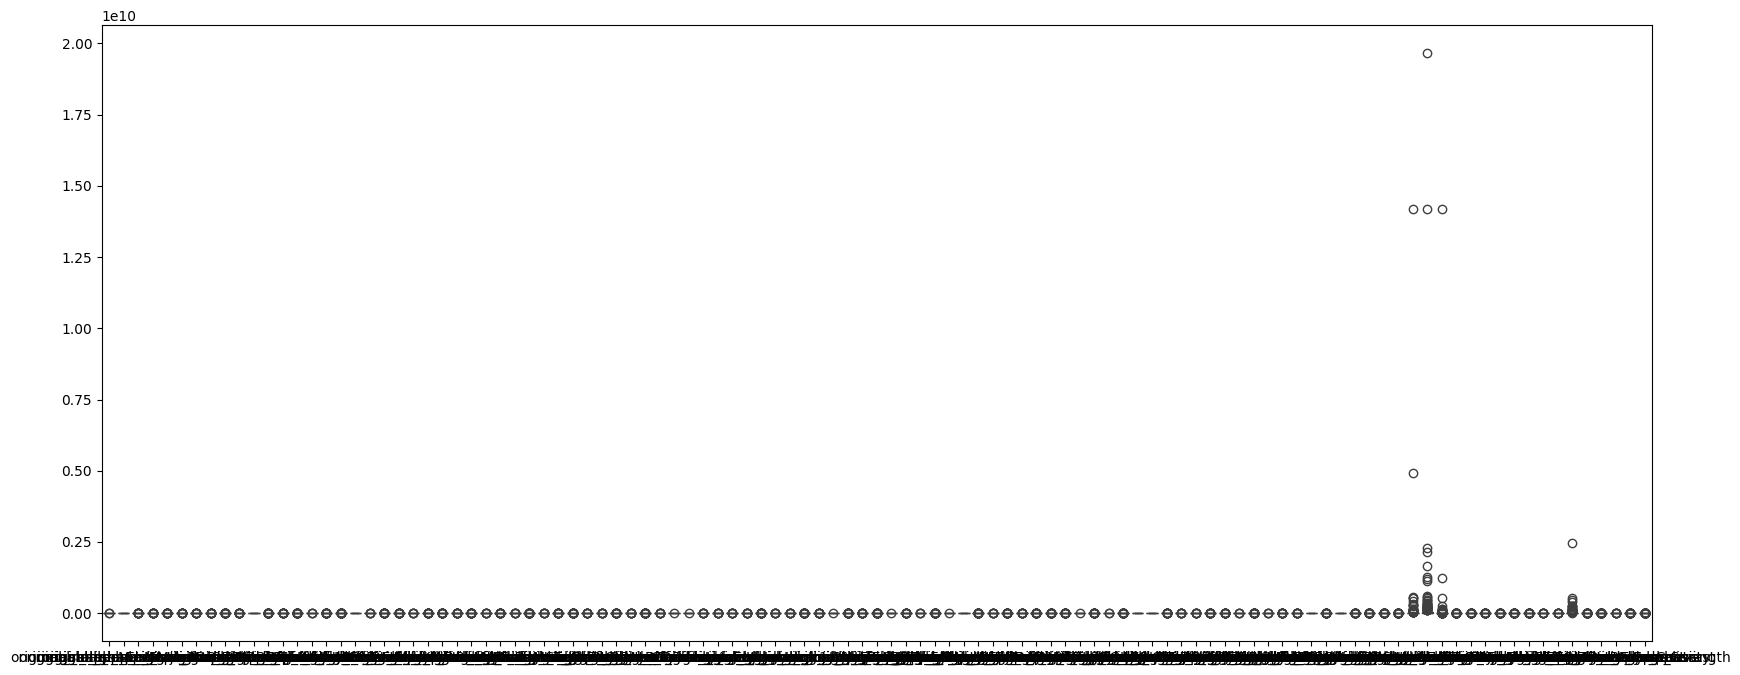

In [11]:
fig, ax = plt.subplots(1, figsize = (20, 8))
sns.boxplot(data = X_train[continuous_names], ax = ax)

In [12]:
# Handle outliers in columns of continuous features using Interquartile Range of the columns
for col in continuous_names:
    lower_quartile = X_train[col].quantile(0.25)
    upper_quartile = X_train[col].quantile(0.75)
    iqr = upper_quartile - lower_quartile

    lower_bound = lower_quartile - 1.5 * iqr
    upper_bound = upper_quartile + 1.5 * iqr
    
    X_train[col] = np.where((X_train[col] < lower_bound) | (X_train[col] > upper_bound), X_train[col].median(), X_train[col])


<Axes: >

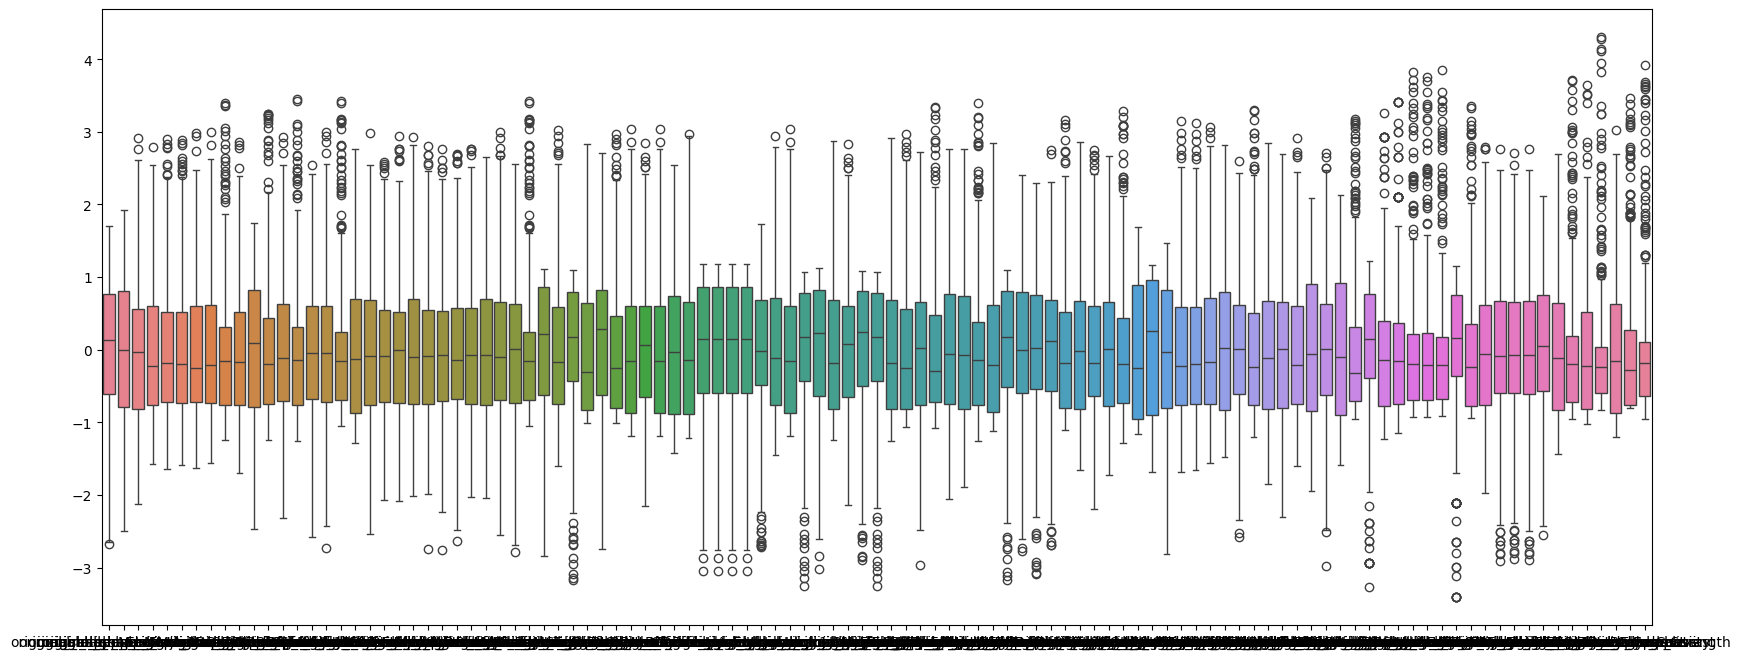

In [13]:
# Apply Z-Score Normalisation to the columns for the continuous features
standard_scaler = StandardScaler()
X_train[continuous_names] = standard_scaler.fit_transform(X_train[continuous_names])
fig, ax = plt.subplots(1, figsize = (20, 8))
sns.boxplot(data = X_train[continuous_names], ax = ax)

In [14]:
# Apply One-Hot Encoding to the columns for the categorical features
X_train_encoded = pd.get_dummies(X_train, columns = categorical_names, drop_first = True)
X_train_encoded

,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,original_shape_MeshVolume,original_shape_MinorAxisLength,...,ChemoGrade_2.0,ChemoGrade_3.0,Proliferation_2.0,Proliferation_3.0,HistologyType_2.0,LNStatus_1.0,TumourStage_2.0,TumourStage_3.0,TumourStage_4.0,Gene_1.0
365,-0.331740,-1.218654,0.605033,1.767606,1.732254,1.084528,1.583962,2.171387,-0.126792,1.837382,...,True,False,False,False,False,True,False,True,False,False
172,0.844836,-0.406867,0.200797,0.289656,0.771266,0.517727,0.650198,0.596312,1.346284,0.987050,...,True,False,False,False,False,False,False,True,False,True
183,0.149633,-0.675431,1.286706,1.537853,0.941608,1.443161,1.148711,1.368889,0.314312,2.047252,...,True,False,False,False,False,False,False,True,False,True
299,-0.043448,-0.578264,-0.649736,-0.291573,0.198472,-0.596488,0.249230,-0.091174,-0.696690,-0.246752,...,True,False,False,False,False,True,True,False,False,False
321,-1.058208,-0.597123,-0.306624,0.024097,-0.407554,-0.387664,0.250769,-0.124087,-0.100603,-0.457660,...,True,False,False,False,True,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,0.203652,-0.066449,1.027190,0.625191,1.119891,1.028004,0.830357,0.873276,2.298539,0.988542,...,True,False,False,False,True,True,False,True,False,False
44,-0.286330,0.224132,0.683602,0.156192,-0.102668,0.492230,0.010506,0.512526,1.266558,0.123960,...,True,False,False,False,False,False,True,False,False,True
63,-1.338589,-0.542346,1.972619,1.943043,-0.178589,0.822513,-0.248878,2.569696,-0.154880,0.965092,...,False,True,True,False,True,True,False,True,False,False
388,-0.386060,0.100366,2.503461,1.509147,1.761823,2.122508,0.856480,1.164910,-0.154880,1.506897,...,False,True,True,False,False,True,False,True,False,False


In [15]:
# Check that there are no longer any missing values for the features of each data point
missing_values = X_train_encoded.isnull().sum()
missing_values = missing_values[missing_values > 0]
missing_values

Series([], dtype: int64)

<h2>Preprocessing for Regression Task</h2>

In [16]:
# Select and assign feature columns to x
x = dataset2.drop(['ID', 'pCR (outcome)', 'RelapseFreeSurvival (outcome)'], axis = 1)
# Select and assign label column to y
y = dataset2['RelapseFreeSurvival (outcome)']
y

0      144.000000
1      142.000000
2      135.000000
3       12.000000
4      109.000000
          ...    
395     54.500000
396     49.250000
397     48.500000
398     47.500000
399     46.916667
Name: RelapseFreeSurvival (outcome), Length: 400, dtype: float64

In [17]:
# Split the dataset into 80% for training data and 20% for test data
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 12)

In [18]:
# Select the columns of the categorical features. These features correspond to the clinical features
X_train['Age'] = X_train['Age'].astype(np.int64)
X_train['original_shape_VoxelVolume'] = X_train['original_shape_VoxelVolume'].astype(np.float64)
categorical_names = X_train.select_dtypes(np.int64).columns
X_train[categorical_names]

,Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,Gene
199,36,0,1,0,0,3,3,1,0,3,999
43,69,0,0,1,0,2,1,1,1,2,1
307,60,0,0,0,1,2,1,1,1,1,999
166,38,1,1,1,0,3,2,1,0,2,1
64,45,0,0,1,0,3,2,1,0,3,1
...,...,...,...,...,...,...,...,...,...,...,...
241,71,0,0,0,1,3,3,1,1,2,999
253,63,0,0,1,0,2,3,1,1,3,1
390,68,0,0,0,1,3,2,1,1,2,0
155,40,1,1,0,0,2,1,1,1,3,1


In [19]:
# Select the columns of the continuous features. These features correspond to the features taken from medical imaging
X_train['original_shape_VoxelVolume'] = X_train['original_shape_VoxelVolume'].astype(np.float64)
continuous_names = X_train.select_dtypes(np.float64).columns
X_train[continuous_names]

,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,original_shape_MeshVolume,original_shape_MinorAxisLength,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
199,0.858831,0.824066,17.709457,21.490331,23.853721,25.059928,22.203603,25.553865,4844.000000,18.456566,...,0.350799,0.350799,3.197160,0.003696,9.762004e+05,74.501409,0.004012,0.102368,0.011175,0.003570
43,0.653366,0.545140,16.727687,30.685113,33.837849,29.154759,30.083218,34.597688,6674.166667,20.048597,...,0.550507,0.550507,2.573220,0.005959,1.052641e+06,21.346044,0.012082,0.024663,0.000567,0.010516
307,0.686668,0.487857,15.812660,32.412492,30.479501,33.015148,34.928498,39.166312,4190.833333,22.256619,...,0.426840,0.426840,2.956748,0.007522,4.830177e+05,38.839662,0.007064,0.066551,0.004116,0.006365
166,0.857085,0.590414,14.907903,25.249927,29.120440,27.892651,27.018512,29.883106,5444.416667,21.641338,...,0.572002,0.572002,2.000000,0.002920,1.720824e+06,8.240840,0.030818,0.011843,0.000150,0.025057
64,0.714724,0.356154,26.727082,75.043710,86.330759,68.468971,81.006173,87.017240,36630.791670,53.635534,...,0.584634,0.583599,2.398050,0.002764,1.202316e+07,163.782516,0.001637,0.033111,0.001479,0.001571
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
241,0.695391,0.626946,39.560926,63.101032,67.416615,68.963759,64.845971,73.088987,43852.833330,43.879916,...,0.411956,0.411956,3.573921,0.004671,8.211440e+06,448.101792,0.000618,0.073363,0.005057,0.000545
253,0.496812,0.282268,24.027355,85.122390,80.653580,75.690158,57.974132,80.962954,25927.166670,42.289823,...,0.409377,0.409376,3.305045,0.001730,6.755623e+06,476.373341,0.000653,0.117835,0.014701,0.000594
390,0.432680,0.378268,17.152942,45.346050,47.634021,39.560081,26.476405,49.648766,7294.708333,19.620346,...,0.476508,0.476508,2.755023,0.004610,1.456280e+06,34.211090,0.007661,0.035392,0.001197,0.006756
155,0.543030,0.401235,19.681554,49.052429,41.761226,43.931765,38.078866,53.094256,10472.291670,26.636953,...,0.404660,0.404660,3.386250,0.003987,2.235835e+06,104.017827,0.002675,0.070976,0.005043,0.002376


In [20]:
# For any values filled with 999, replace them with NaN to indicate that these values are missing
X_train.replace(to_replace = 999, value = np.nan, inplace = True)
missing_values = X_train.isnull().sum()
missing_values = missing_values[missing_values > 0]
missing_values

ChemoGrade        3
Proliferation     2
HistologyType     3
LNStatus          1
Gene             69
dtype: int64

In [21]:
# For the categorical features, impute the missing values in each column with the mode of that column
modal_imputer = SimpleImputer(missing_values = np.nan, strategy = 'most_frequent')
X_train[categorical_names] = modal_imputer.fit_transform(X_train[categorical_names])
X_train[categorical_names].head()

,Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,Gene
199,36.0,0.0,1.0,0.0,0.0,3.0,3.0,1.0,0.0,3.0,0.0
43,69.0,0.0,0.0,1.0,0.0,2.0,1.0,1.0,1.0,2.0,1.0
307,60.0,0.0,0.0,0.0,1.0,2.0,1.0,1.0,1.0,1.0,0.0
166,38.0,1.0,1.0,1.0,0.0,3.0,2.0,1.0,0.0,2.0,1.0
64,45.0,0.0,0.0,1.0,0.0,3.0,2.0,1.0,0.0,3.0,1.0


<Axes: >

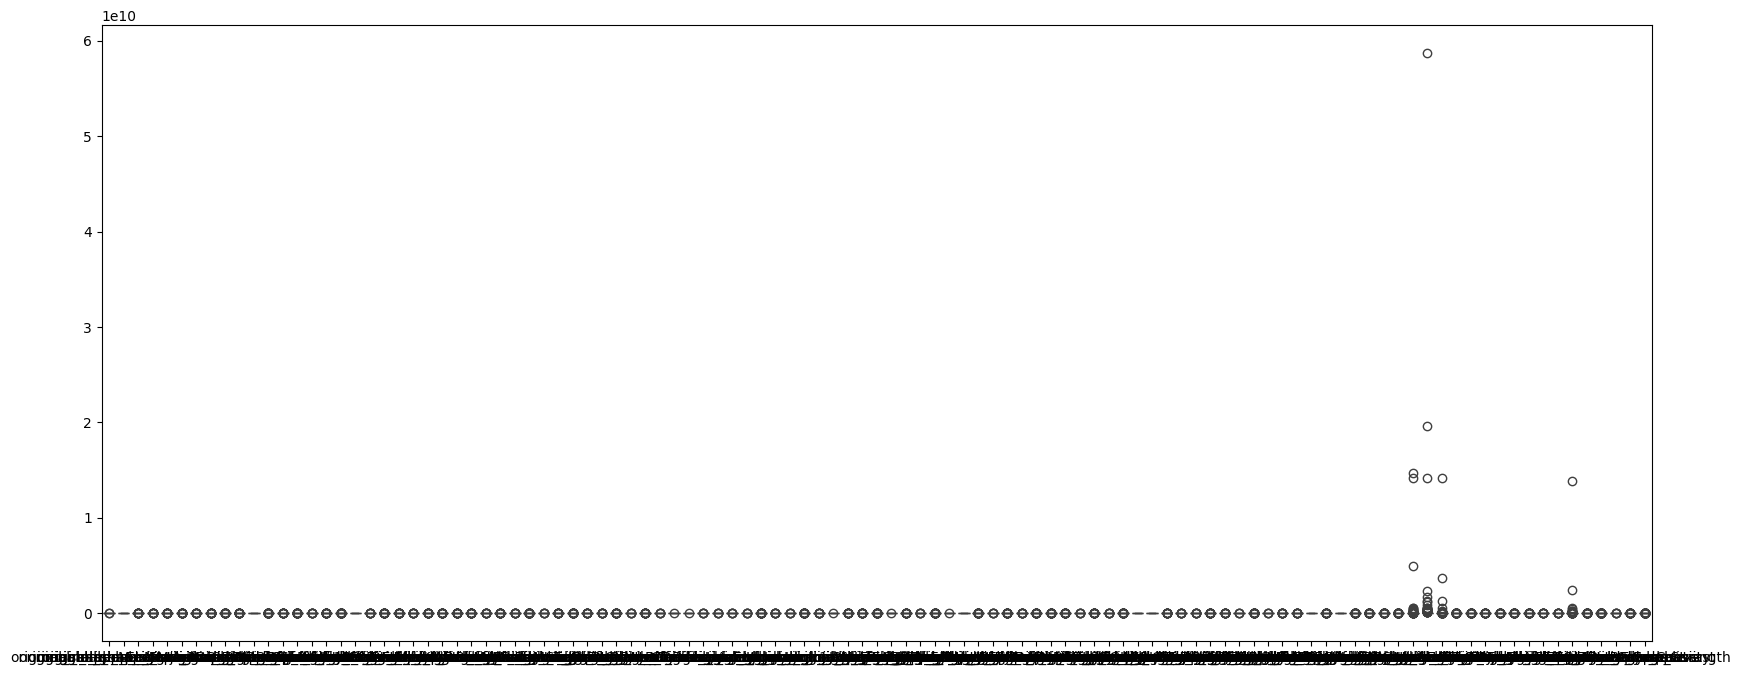

In [22]:
fig, ax = plt.subplots(1, figsize = (20, 8))
sns.boxplot(data = X_train[continuous_names], ax = ax)

In [23]:
# Handle outliers in columns of continuous features using Interquartile Range of the columns
for col in continuous_names:
    lower_quartile = X_train[col].quantile(0.25)
    upper_quartile = X_train[col].quantile(0.75)
    iqr = upper_quartile - lower_quartile

    lower_bound = lower_quartile - 1.5 * iqr
    upper_bound = upper_quartile + 1.5 * iqr
    
    X_train[col] = np.where((X_train[col] < lower_bound) | (X_train[col] > upper_bound), X_train[col].median(), X_train[col])

<Axes: >

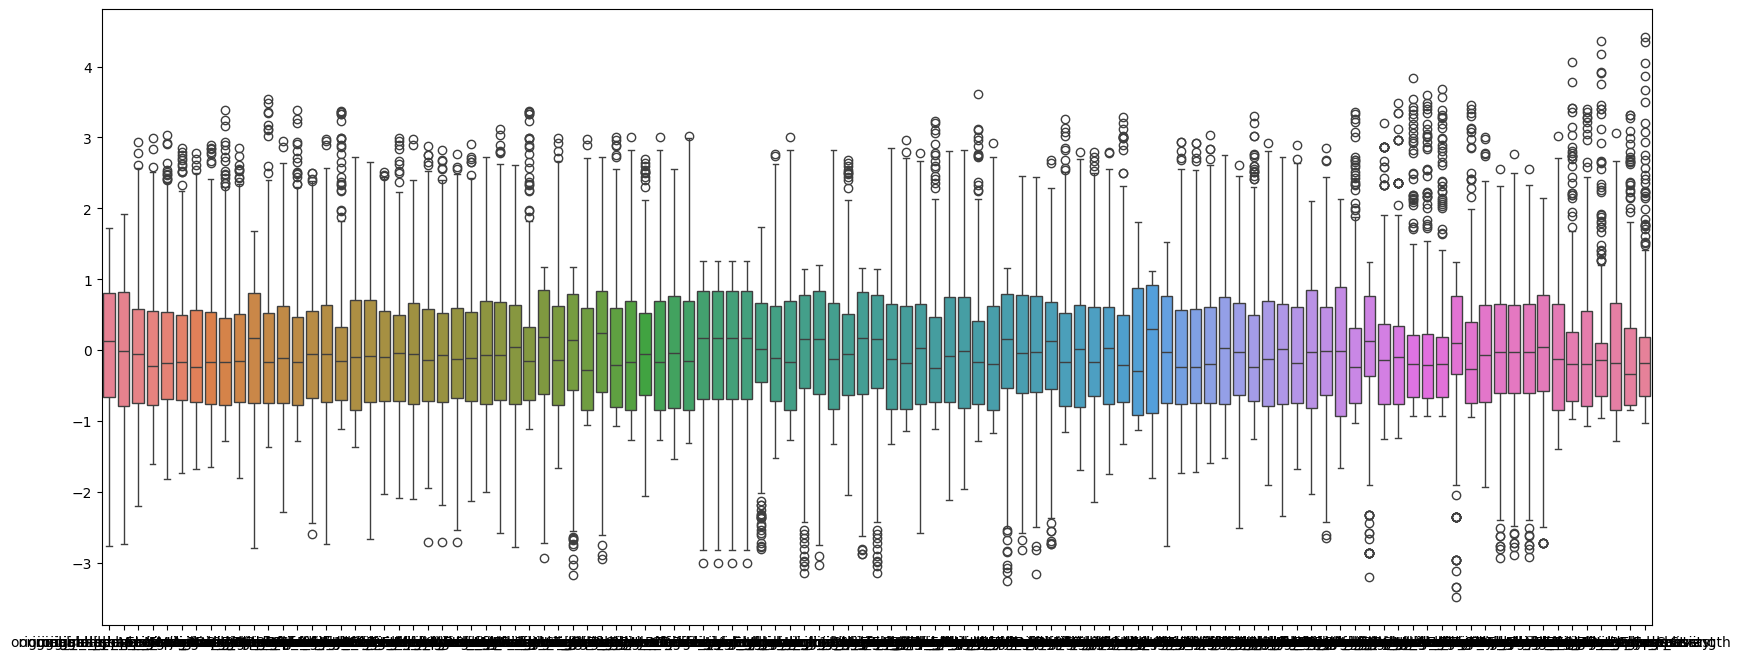

In [24]:
# Apply Z-Score Normalisation to the columns for the continuous features
standard_scaler = StandardScaler()
X_train[continuous_names] = standard_scaler.fit_transform(X_train[continuous_names])
fig, ax = plt.subplots(1, figsize = (20, 8))
sns.boxplot(data = X_train[continuous_names], ax = ax)

In [25]:
# Apply One-Hot Encoding to the columns for the categorical features
X_train_encoded = pd.get_dummies(X_train, columns = categorical_names, drop_first = True)
X_train_encoded

,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,original_shape_MeshVolume,original_shape_MinorAxisLength,...,ChemoGrade_2.0,ChemoGrade_3.0,Proliferation_2.0,Proliferation_3.0,HistologyType_2.0,LNStatus_1.0,TumourStage_2.0,TumourStage_3.0,TumourStage_4.0,Gene_1.0
199,0.898274,1.661433,-0.587727,-1.139421,-1.154646,-0.984168,-1.186815,-1.193097,-0.870068,-0.983719,...,False,True,False,True,False,False,False,True,False,False
43,-0.443542,-0.029533,-0.717309,-0.664226,-0.591134,-0.731139,-0.757427,-0.778187,-0.693184,-0.842309,...,True,False,False,False,False,True,True,False,False,True
307,-0.226057,-0.376807,-0.838082,-0.574954,-0.780682,-0.492597,-0.493390,-0.568589,-0.933196,-0.646184,...,True,False,False,False,False,True,False,False,False,False
166,0.886872,0.244935,-0.957499,-0.945122,-0.857389,-0.809128,-0.924433,-0.994481,-0.812038,-0.700836,...,False,True,True,False,False,False,True,False,False,True
64,-0.042835,-1.175248,0.602492,1.628266,2.371606,1.698173,2.017549,1.626700,2.202099,2.141008,...,False,True,True,False,False,False,False,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
241,-0.169088,0.466407,2.296408,1.011058,1.304077,1.728747,1.136921,0.987704,2.900103,1.274478,...,False,True,False,True,False,True,True,False,False,False
253,-1.465934,-1.623170,0.246160,2.149142,2.051182,2.144386,0.762450,1.348944,1.167602,1.133240,...,True,False,False,True,False,True,False,True,False,True
390,-1.884752,-1.041183,-0.661181,0.093464,0.187532,-0.088172,-0.953975,-0.087678,-0.633209,-0.880348,...,False,True,True,False,False,True,True,False,False,False
155,-1.164100,-0.901945,-0.327434,0.285013,-0.143933,0.181964,-0.321715,0.070393,-0.326098,-0.257106,...,True,False,False,False,False,True,False,True,False,True


In [26]:
# Check that there are no longer any missing values for the features of each data point
missing_values = X_train_encoded.isnull().sum()
missing_values = missing_values[missing_values > 0]
missing_values

Series([], dtype: int64)